In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import cv2
from PIL import Image

# Project paths
PROJECT_PATH = Path(r"D:\FINAL DFDT")
DATASET_PATH = PROJECT_PATH / "SELECTED_DATASET"

SPLIT_CSV = DATASET_PATH / "splits" / "dataset_split_manifest.csv"

# Verify paths
print("PROJECT:", PROJECT_PATH.exists())
print("DATASET:", DATASET_PATH.exists())
print("SPLIT CSV:", SPLIT_CSV.exists())

# Load existing split manifest
split_manifest = pd.read_csv(SPLIT_CSV)

print("\nDataset shape:", split_manifest.shape)
print("\nColumns:")
print(split_manifest.columns.tolist())

print("\nSplit distribution:")
print(split_manifest["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(split_manifest["split"], split_manifest["class"]))

print("\nMissing values:")
print(split_manifest.isnull().sum())

# Reconstruct image paths
split_manifest["image_path"] = split_manifest.apply(
    lambda row: str(
        DATASET_PATH /
        row["class"].lower() /
        Path(row["destination_image"]).name
    ),
    axis=1
)

missing_images = sum(
    not Path(path).exists()
    for path in split_manifest["image_path"]
)

print("\nMissing image files:", missing_images)

assert len(split_manifest) == 10000
assert missing_images == 0

print("\nSTEP 30.1 VERIFICATION PASSED")


PROJECT: True
DATASET: True
SPLIT CSV: True

Dataset shape: (10000, 5)

Columns:
['class', 'source_subfolder', 'source_image', 'destination_image', 'split']

Split distribution:
split
train         7000
test          1500
validation    1500
Name: count, dtype: int64

Class distribution:
class       FAKE  REAL
split                 
test         750   750
train       3500  3500
validation   750   750

Missing values:
class                0
source_subfolder     0
source_image         0
destination_image    0
split                0
dtype: int64

Missing image files: 0

STEP 30.1 VERIFICATION PASSED


In [2]:

import numpy as np
import cv2
from pathlib import Path

IMG_SIZE = 160

def extract_degradation_descriptors_160(image_path):

    # Load image as RGB
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize to 160 x 160
    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray_float = gray.astype(np.float32) / 255.0

    # 1. Brightness
    brightness = np.mean(gray_float)

    # 2. Contrast
    contrast = np.std(gray_float)

    # 3. Sharpness
    sharpness = cv2.Laplacian(
        gray_float, cv2.CV_32F
    ).var()

    # 4. Residual energy
    blurred = cv2.GaussianBlur(
        gray_float, (5, 5), 0
    )
    residual = gray_float - blurred
    residual_energy = np.mean(residual ** 2)

    # 5. Absolute residual
    absolute_residual = np.mean(np.abs(residual))

    # 6–8. FFT frequency energy
    fft = np.fft.fftshift(
        np.fft.fft2(gray_float)
    )

    magnitude = np.abs(fft) ** 2

    height, width = gray.shape
    center_y = height // 2
    center_x = width // 2

    y, x = np.ogrid[:height, :width]

    distance = np.sqrt(
        (y - center_y) ** 2 +
        (x - center_x) ** 2
    )

    max_distance = np.sqrt(
        center_y ** 2 + center_x ** 2
    )

    normalized_distance = distance / max_distance

    low_mask = normalized_distance < 0.15

    mid_mask = (
        (normalized_distance >= 0.15) &
        (normalized_distance < 0.50)
    )

    high_mask = normalized_distance >= 0.50

    total_energy = np.sum(magnitude) + 1e-8

    low_frequency_energy = (
        np.sum(magnitude[low_mask]) / total_energy
    )

    mid_frequency_energy = (
        np.sum(magnitude[mid_mask]) / total_energy
    )

    high_frequency_energy = (
        np.sum(magnitude[high_mask]) / total_energy
    )

    return np.array([
        brightness,
        contrast,
        sharpness,
        residual_energy,
        absolute_residual,
        low_frequency_energy,
        mid_frequency_energy,
        high_frequency_energy
    ], dtype=np.float32)


In [3]:

# Select one training image
sample_row = split_manifest[
    split_manifest["split"] == "train"
].iloc[0]

sample_path = sample_row["image_path"]

sample_features = extract_degradation_descriptors_160(
    sample_path
)

print("Image:", sample_path)
print("Descriptor shape:", sample_features.shape)
print("\nDescriptor values:")

descriptor_names = [
    "Brightness",
    "Contrast",
    "Sharpness",
    "Residual Energy",
    "Absolute Residual",
    "FFT Low",
    "FFT Mid",
    "FFT High"
]

for name, value in zip(descriptor_names, sample_features):
    print(f"{name}: {value:.8f}")

assert sample_features.shape == (8,)
assert np.all(np.isfinite(sample_features))

print("\nSTEP 30.3 TEST PASSED")


Image: D:\FINAL DFDT\SELECTED_DATASET\real\000_01_191.png
Descriptor shape: (8,)

Descriptor values:
Brightness: 0.63935280
Contrast: 0.23768118
Sharpness: 0.00552020
Residual Energy: 0.00068783
Absolute Residual: 0.01315756
FFT Low: 0.99331647
FFT Mid: 0.00635029
FFT High: 0.00033305

STEP 30.3 TEST PASSED


In [4]:

import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm

# Output directory
FEATURE_DIR = DATASET_PATH / "degradation_features_160"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_CSV = FEATURE_DIR / "degradation_features_160_raw.csv"

# Descriptor names
descriptor_names = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

# Extract descriptors for all images
all_features = []

for _, row in tqdm(
    split_manifest.iterrows(),
    total=len(split_manifest),
    desc="Extracting 160x160 descriptors"
):
    features = extract_degradation_descriptors_160(
        row["image_path"]
    )

    record = {
        "class": row["class"],
        "source_subfolder": row["source_subfolder"],
        "source_image": row["source_image"],
        "destination_image": row["destination_image"],
        "split": row["split"]
    }

    for name, value in zip(descriptor_names, features):
        record[name] = float(value)

    all_features.append(record)

# Create DataFrame
features_df = pd.DataFrame(all_features)

# Verification
print("Dataset shape:", features_df.shape)
print("\nSplit distribution:")
print(features_df["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(features_df["split"], features_df["class"]))

# Check missing values
print("\nMissing values:", features_df.isnull().sum().sum())

# Check finite descriptor values
descriptor_array = features_df[descriptor_names].to_numpy()

print("NaN values:", np.isnan(descriptor_array).sum())
print("Infinite values:", np.isinf(descriptor_array).sum())

assert len(features_df) == 10000
assert features_df.isnull().sum().sum() == 0
assert np.isfinite(descriptor_array).all()

# Save raw descriptors
features_df.to_csv(OUTPUT_CSV, index=False)

print("\nSaved:", OUTPUT_CSV)
print("\nSTEP 30.4 EXTRACTION PASSED")


Extracting 160x160 descriptors: 100%|██████████| 10000/10000 [00:31<00:00, 320.29it/s]


Dataset shape: (10000, 13)

Split distribution:
split
train         7000
test          1500
validation    1500
Name: count, dtype: int64

Class distribution:
class       FAKE  REAL
split                 
test         750   750
train       3500  3500
validation   750   750

Missing values: 0
NaN values: 0
Infinite values: 0

Saved: D:\FINAL DFDT\SELECTED_DATASET\degradation_features_160\degradation_features_160_raw.csv

STEP 30.4 EXTRACTION PASSED


In [5]:

import json
import numpy as np
import pandas as pd

# Load extracted descriptors
features_df = pd.read_csv(OUTPUT_CSV)

descriptor_names = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

# Separate training data
train_features = features_df.loc[
    features_df["split"] == "train",
    descriptor_names
]

assert len(train_features) == 7000

# Calculate training-only normalization parameters
train_mean = train_features.mean()
train_std = train_features.std(ddof=0)

# Protect against zero standard deviation
train_std = train_std.replace(0, 1.0)

# Normalize all splits using training statistics
normalized_df = features_df.copy()

normalized_df[descriptor_names] = (
    features_df[descriptor_names] - train_mean
) / train_std

# Verify normalized training data
normalized_train = normalized_df.loc[
    normalized_df["split"] == "train",
    descriptor_names
]

print("TRAINING NORMALIZATION VERIFICATION")
print("=" * 65)

print(normalized_train.describe().T.round(4))

# Check finite values
normalized_values = normalized_df[descriptor_names].to_numpy()

assert np.isfinite(normalized_values).all()

# Save normalized descriptors
NORMALIZED_CSV = (
    FEATURE_DIR / "degradation_features_160_normalized.csv"
)

normalized_df.to_csv(NORMALIZED_CSV, index=False)

# Save normalization parameters
normalization_params = {
    "image_size": 160,
    "descriptor_names": descriptor_names,
    "normalization_method": "z-score",
    "standard_deviation_ddof": 0,
    "fitted_on": "train",
    "training_sample_count": int(len(train_features)),
    "mean": train_mean.to_dict(),
    "std": train_std.to_dict()
}

NORMALIZATION_JSON = (
    FEATURE_DIR / "descriptor_normalization_160.json"
)

with open(NORMALIZATION_JSON, "w") as f:
    json.dump(normalization_params, f, indent=4)

print("\nNormalized CSV:", NORMALIZED_CSV)
print("Normalization JSON:", NORMALIZATION_JSON)

print("\nNaN:", np.isnan(normalized_values).sum())
print("Infinite:", np.isinf(normalized_values).sum())

print("\nSTEP 30.5 NORMALIZATION COMPLETED")


TRAINING NORMALIZATION VERIFICATION
                    count  mean     std      min     25%     50%     75%  \
brightness         7000.0  -0.0  1.0001  -2.4425 -0.7079 -0.1119  0.5649   
contrast           7000.0  -0.0  1.0001  -2.5556 -0.7192 -0.0872  0.5858   
sharpness          7000.0  -0.0  1.0001  -0.9728 -0.5777 -0.2741  0.2480   
residual_energy    7000.0   0.0  1.0001  -1.1158 -0.5750 -0.2450  0.2496   
absolute_residual  7000.0   0.0  1.0001  -1.8790 -0.6693 -0.1652  0.4583   
fft_low            7000.0  -0.0  1.0001 -14.1843 -0.3700  0.1779  0.6060   
fft_mid            7000.0   0.0  1.0001  -1.4966 -0.6106 -0.1855  0.3785   
fft_high           7000.0   0.0  1.0001  -0.9060 -0.5038 -0.2104  0.2432   

                       max  
brightness          3.7322  
contrast            3.8584  
sharpness          10.0205  
residual_energy    13.4193  
absolute_residual   8.2492  
fft_low             1.4667  
fft_mid            12.8285  
fft_high           22.0982  

Normalized CSV: D

In [6]:

# Identify the most extreme normalized values
for descriptor in descriptor_names:
    print(f"\n{'=' * 65}")
    print("DESCRIPTOR:", descriptor)

    lowest = normalized_df.nsmallest(3, descriptor)
    highest = normalized_df.nlargest(3, descriptor)

    print("\nLowest 3:")
    print(lowest[
        ["class", "split", "destination_image", descriptor]
    ].to_string(index=False))

    print("\nHighest 3:")
    print(highest[
        ["class", "split", "destination_image", descriptor]
    ].to_string(index=False))

print("\nSTEP 30.6 EXTREME VALUE INSPECTION COMPLETED")



DESCRIPTOR: brightness

Lowest 3:
class split                                       destination_image  brightness
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\344_020_03_406.png   -2.442484
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\344_020_05_528.png   -2.435155
 REAL train     E:\FINAL DATA1\SELECTED_DATASET\real\344_04_203.png   -2.373922

Highest 3:
class split                                       destination_image  brightness
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\533_450_04_359.png    3.732216
 REAL train     E:\FINAL DATA1\SELECTED_DATASET\real\533_01_107.png    3.703335
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\533_450_05_431.png    3.702804

DESCRIPTOR: contrast

Lowest 3:
class      split                                   destination_image  contrast
 REAL validation E:\FINAL DATA1\SELECTED_DATASET\real\581_03_073.png -2.736958
 REAL validation E:\FINAL DATA1\SELECTED_DATASET\real\581_04_061.png -2.714102
 REAL validation E:\FINAL DATA1\SELECTED_DA

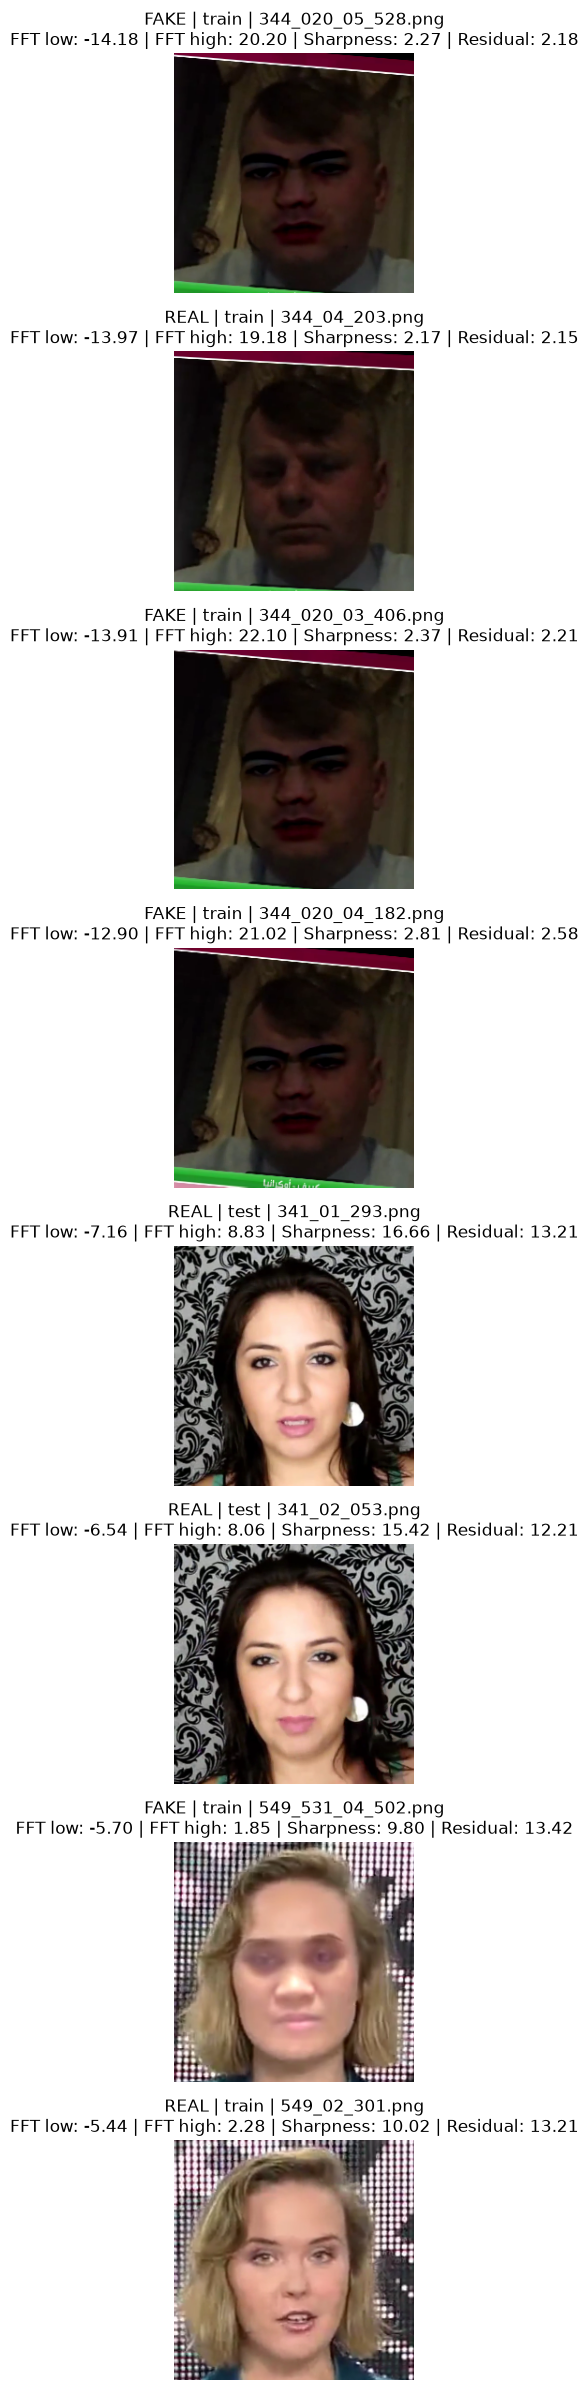

Images inspected: 8


In [7]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Connect descriptor records to the actual current dataset paths
inspection_df = normalized_df.copy()

inspection_df["image_path"] = inspection_df[
    "destination_image"
].apply(
    lambda x: str(DATASET_PATH / 
                  inspection_df.loc[
                      inspection_df["destination_image"] == x,
                      "class"
                  ].iloc[0].lower() / Path(x).name)
)

# Select representative extremes
selected_rows = []

for descriptor, direction in [
    ("fft_low", "lowest"),
    ("fft_high", "highest"),
    ("sharpness", "highest"),
    ("residual_energy", "highest"),
    ("absolute_residual", "highest")
]:
    if direction == "highest":
        selected_rows.append(
            inspection_df.nlargest(2, descriptor)
        )
    else:
        selected_rows.append(
            inspection_df.nsmallest(2, descriptor)
        )

extreme_images = pd.concat(selected_rows).drop_duplicates(
    subset=["destination_image"]
).reset_index(drop=True)

# Display images and descriptor values
fig, axes = plt.subplots(
    len(extreme_images), 1,
    figsize=(12, len(extreme_images) * 3)
)

if len(extreme_images) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, extreme_images.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        f'{row["class"]} | {row["split"]} | '
        f'{Path(row["image_path"]).name}\n'
        f'FFT low: {row["fft_low"]:.2f} | '
        f'FFT high: {row["fft_high"]:.2f} | '
        f'Sharpness: {row["sharpness"]:.2f} | '
        f'Residual: {row["residual_energy"]:.2f}'
    )

plt.tight_layout()
plt.show()

print("Images inspected:", len(extreme_images))


In [8]:

# Verify final descriptor files

raw_check = pd.read_csv(OUTPUT_CSV)
normalized_check = pd.read_csv(NORMALIZED_CSV)

with open(NORMALIZATION_JSON, "r") as f:
    params_check = json.load(f)

assert len(raw_check) == 10000
assert len(normalized_check) == 10000

assert raw_check["split"].value_counts().to_dict() == {
    "train": 7000,
    "test": 1500,
    "validation": 1500
}

assert params_check["fitted_on"] == "train"
assert params_check["training_sample_count"] == 7000

assert np.isfinite(
    normalized_check[descriptor_names].to_numpy()
).all()

# Confirm metadata consistency
metadata_columns = [
    "class",
    "source_subfolder",
    "source_image",
    "destination_image",
    "split"
]

assert raw_check[metadata_columns].equals(
    normalized_check[metadata_columns]
)

print("Raw descriptor rows:", len(raw_check))
print("Normalized descriptor rows:", len(normalized_check))
print("Descriptor count:", len(descriptor_names))
print("Training samples:", (normalized_check["split"] == "train").sum())
print("Validation samples:", (normalized_check["split"] == "validation").sum())
print("Test samples:", (normalized_check["split"] == "test").sum())
print("Normalization fitted on:", params_check["fitted_on"])
print("Metadata consistency: PASS")
print("Finite-value verification: PASS")

print("\nSTEP 30.8 FINAL VERIFICATION PASSED")


Raw descriptor rows: 10000
Normalized descriptor rows: 10000
Descriptor count: 8
Training samples: 7000
Validation samples: 1500
Test samples: 1500
Normalization fitted on: train
Metadata consistency: PASS
Finite-value verification: PASS

STEP 30.8 FINAL VERIFICATION PASSED


In [9]:

import torch
from torch.utils.data import Dataset
from PIL import Image
import pandas as pd
import numpy as np
from pathlib import Path

# Load normalized descriptor dataset
training_df = pd.read_csv(NORMALIZED_CSV)

# Exact descriptor order expected by the model
DESCRIPTOR_COLUMNS = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

# Explicit class mapping
CLASS_TO_LABEL = {
    "REAL": 0,
    "FAKE": 1
}

class AMSFDataset(Dataset):

    def __init__(self, dataframe, dataset_path):
        self.dataframe = dataframe.reset_index(drop=True)
        self.dataset_path = Path(dataset_path)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Reconstruct actual image path
        image_path = (
            self.dataset_path /
            row["class"].lower() /
            Path(row["destination_image"]).name
        )

        # Load and preprocess image
        image = Image.open(image_path).convert("RGB")

        image = image.resize(
            (160, 160),
            Image.Resampling.BILINEAR
        )

        image_array = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        # HWC -> CHW
        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        )

        # Load normalized degradation descriptors
        descriptor_array = row[
            DESCRIPTOR_COLUMNS
        ].to_numpy(dtype=np.float32)

        descriptor_tensor = torch.from_numpy(
            descriptor_array.copy()
        )

        # REAL = 0, FAKE = 1
        label = CLASS_TO_LABEL[row["class"]]
        label_tensor = torch.tensor(
            label,
            dtype=torch.long
        )

        return {
            "image": image_tensor,
            "descriptors": descriptor_tensor,
            "label": label_tensor
        }


# Create a small training dataset for verification
train_df = training_df[
    training_df["split"] == "train"
].copy()

train_dataset = AMSFDataset(
    train_df,
    DATASET_PATH
)

print("Training dataset size:", len(train_dataset))

# Inspect one sample
sample = train_dataset[0]

print("\nSAMPLE VERIFICATION")
print("Image shape:", sample["image"].shape)
print("Descriptor shape:", sample["descriptors"].shape)
print("Label:", sample["label"].item())

print("\nIMAGE RANGE")
print("Minimum:", sample["image"].min().item())
print("Maximum:", sample["image"].max().item())

print("\nDESCRIPTOR FINITE:", torch.isfinite(
    sample["descriptors"]
).all().item())

assert sample["image"].shape == (3, 160, 160)
assert sample["descriptors"].shape == (8,)
assert sample["image"].min() >= 0
assert sample["image"].max() <= 1
assert sample["label"].item() in [0, 1]
assert torch.isfinite(sample["descriptors"]).all()

print("\nSTEP 31.1 DATASET VERIFICATION PASSED")


Training dataset size: 7000

SAMPLE VERIFICATION
Image shape: torch.Size([3, 160, 160])
Descriptor shape: torch.Size([8])
Label: 0

IMAGE RANGE
Minimum: 0.03529411926865578
Maximum: 1.0

DESCRIPTOR FINITE: True

STEP 31.1 DATASET VERIFICATION PASSED


In [10]:

from torch.utils.data import DataLoader

# Separate all three splits
train_df = training_df[
    training_df["split"] == "train"
].copy()

val_df = training_df[
    training_df["split"] == "validation"
].copy()

test_df = training_df[
    training_df["split"] == "test"
].copy()

# Create datasets
train_dataset = AMSFDataset(train_df, DATASET_PATH)
val_dataset = AMSFDataset(val_df, DATASET_PATH)
test_dataset = AMSFDataset(test_df, DATASET_PATH)

# Initial conservative batch size
BATCH_SIZE = 4

# GPU configuration
PIN_MEMORY = torch.cuda.is_available()

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

print("DATASET SIZES")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

print("\nDATALOADER BATCH COUNTS")
print("Training:", len(train_loader))
print("Validation:", len(val_loader))
print("Testing:", len(test_loader))

print("\nBATCH SIZE:", BATCH_SIZE)
print("PIN MEMORY:", PIN_MEMORY)

# Inspect one batch from each loader
for split_name, loader in [
    ("TRAIN", train_loader),
    ("VALIDATION", val_loader),
    ("TEST", test_loader)
]:

    batch = next(iter(loader))

    print(f"\n{split_name} BATCH")
    print("Images:", batch["image"].shape)
    print("Descriptors:", batch["descriptors"].shape)
    print("Labels:", batch["label"].shape)

    assert batch["image"].shape[1:] == (3, 160, 160)
    assert batch["descriptors"].shape[1:] == (8,)
    assert batch["label"].dtype == torch.long

print("\nSTEP 31.2 DATALOADER VERIFICATION PASSED")


DATASET SIZES
Training: 7000
Validation: 1500
Testing: 1500

DATALOADER BATCH COUNTS
Training: 1750
Validation: 375
Testing: 375

BATCH SIZE: 4
PIN MEMORY: True

TRAIN BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

VALIDATION BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

TEST BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

STEP 31.2 DATALOADER VERIFICATION PASSED


In [11]:

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA available:", torch.cuda.is_available())
else:
    print("Running on CPU")


Selected device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA available: True


In [12]:

required_variables = [
    "AMSFGNetV2",
    "spatial_backbone",
    "frequency_extractor",
    "frequency_encoder",
    "residual_extractor",
    "model_A",
    "model_B"
]

print("ARCHITECTURE VARIABLE CHECK")
print("=" * 50)

for variable in required_variables:
    exists = variable in globals()
    print(f"{variable}: {'AVAILABLE' if exists else 'MISSING'}")


ARCHITECTURE VARIABLE CHECK
AMSFGNetV2: MISSING
spatial_backbone: MISSING
frequency_extractor: MISSING
frequency_encoder: MISSING
residual_extractor: MISSING
model_A: MISSING
model_B: MISSING


In [13]:
print("Model A available:", "model_A" in globals())
print("Model B available:", "model_B" in globals())

if "model_A" in globals() and "model_B" in globals():
    print("\nModel A parameters:",
          sum(p.numel() for p in model_A.parameters()))

    print("Model B parameters:",
          sum(p.numel() for p in model_B.parameters()))

    print("\nARCHITECTURE RESTORATION PASSED")

Model A available: False
Model B available: False


In [14]:

print("MODEL RESTORATION CHECK")
print("=" * 45)

print("AMSFGNetV2:", "AMSFGNetV2" in globals())
print("Model A:", "model_A" in globals())
print("Model B:", "model_B" in globals())

if "model_A" in globals() and "model_B" in globals():

    print("\nModel A parameters:",
          sum(p.numel() for p in model_A.parameters()))

    print("Model B parameters:",
          sum(p.numel() for p in model_B.parameters()))

    print("\nModel A device:",
          next(model_A.parameters()).device)

    print("Model B device:",
          next(model_B.parameters()).device)

    print("\nARCHITECTURE RESTORATION PASSED")


MODEL RESTORATION CHECK
AMSFGNetV2: False
Model A: False
Model B: False


In [15]:

import torch
import gc

# Get one real training batch
batch = next(iter(train_loader))

images = batch["image"].to(DEVICE)
descriptors = batch["descriptors"].to(DEVICE)
labels = batch["label"].to(DEVICE)

print("INPUT VERIFICATION")
print("Images:", images.shape)
print("Descriptors:", descriptors.shape)
print("Labels:", labels.shape)

models_to_test = {
    "Model A - Full AMSF-GNet V2": model_A,
    "Model B - Without Reliability": model_B
}

for model_name, model in models_to_test.items():

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    model = model.to(DEVICE)
    model.eval()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    with torch.inference_mode():
        output = model(images, descriptors)

    logits = output["logits"]

    print("Logits shape:", logits.shape)
    print("Predictions:", torch.argmax(logits, dim=1).cpu().tolist())
    print("Actual labels:", labels.cpu().tolist())

    print("Reliability shape:",
          output["reliability_scores"].shape)

    print("Graph attention shape:",
          output["graph_attention"].shape)

    print("Gate weights shape:",
          output["gate_weights"].shape)

    print("Finite logits:",
          torch.isfinite(logits).all().item())

    print("Gate weights sum:",
          output["gate_weights"].sum(dim=1).cpu().tolist())

    assert logits.shape == (4, 2)
    assert output["reliability_scores"].shape == (4, 3)
    assert output["graph_attention"].shape == (4, 4, 3, 3)
    assert output["gate_weights"].shape == (4, 3)
    assert torch.isfinite(logits).all()
    assert torch.allclose(
        output["gate_weights"].sum(dim=1),
        torch.ones(4, device=DEVICE),
        atol=1e-5
    )

    if torch.cuda.is_available():
        print("Peak GPU memory:",
              round(torch.cuda.max_memory_allocated() / 1024**3, 3),
              "GB")

    del output
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nSTEP 31.3 MODEL FORWARD VERIFICATION PASSED")


INPUT VERIFICATION
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])


NameError: name 'model_A' is not defined